# Análisis espacial y storytelling: Dengue en Argentina (2023)

## Objetivo

Analizar la distribución territorial de los casos de dengue en Argentina
durante las semanas epidemiológicas 1 a 52 de 2023, comparando los
casos absolutos con la incidencia por cada 100.000 habitantes.

## Pregunta central

¿La distribución territorial de los casos de dengue refleja también
dónde fue mayor la carga epidemiológica relativa?

## Enfoque

A partir de los datos provinciales preparados en el notebook anterior,
se identificarán patrones espaciales y contrastes entre jurisdicciones.

Las visualizaciones se seleccionarán según su capacidad para responder
la pregunta central y comunicar los hallazgos de manera clara.

In [1]:
from pathlib import Path

import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors

In [2]:
BASE_DIR = Path.cwd()
PROJECT_DIR = BASE_DIR.parent

PROCESSED_DIR = PROJECT_DIR / "data" / "processed"

CSV_FILE = PROCESSED_DIR / "dengue_analisis_provincial_2023.csv"
GEOJSON_FILE = PROCESSED_DIR / "dengue_provincias_2023.geojson"

print("Directorio del proyecto:", PROJECT_DIR)
print("CSV encontrado:", CSV_FILE.exists())
print("GeoJSON encontrado:", GEOJSON_FILE.exists())

Directorio del proyecto: C:\Users\luisi\Desktop\Bioinformatica\Data Science\Data science II\dengue_spatial_storytelling
CSV encontrado: True
GeoJSON encontrado: True


In [3]:
df_analisis = pd.read_csv(CSV_FILE)

gdf_analisis = gpd.read_file(GEOJSON_FILE)

print("Tabla provincial:", df_analisis.shape)
print("Datos geográficos:", gdf_analisis.shape)

C:\Users\luisi\anaconda3\envs\openfda_ds\Lib\site-packages\pyogrio\core.py:38: RuntimeWarning: Could not detect GDAL data files. Set GDAL_DATA environment variable to the correct path.
  _init_gdal_data()


Tabla provincial: (24, 6)
Datos geográficos: (24, 15)


In [4]:
print("Provincias en la tabla:", len(df_analisis))
print("Provincias en el GeoDataFrame:", len(gdf_analisis))

print("\nSistema de coordenadas:")
print(gdf_analisis.crs)

print("\nValores faltantes:")
print(gdf_analisis[
    ["provincia_residencia", "casos", "poblacion_2023", "incidencia_100mil"]
].isna().sum())

print("\nPrimeros registros:")
display(
    gdf_analisis[
        ["provincia_residencia", "casos", "poblacion_2023", "incidencia_100mil"]
    ].head()
) 

Provincias en la tabla: 24
Provincias en el GeoDataFrame: 24

Sistema de coordenadas:
EPSG:4326

Valores faltantes:
provincia_residencia    0
casos                   0
poblacion_2023          0
incidencia_100mil       0
dtype: int64

Primeros registros:


,provincia_residencia,casos,poblacion_2023,incidencia_100mil
0,CABA,13292,3107894,427.685114
1,Neuquén,39,693935,5.620123
2,San Luis,65,530792,12.245851
3,Santa Fe,21328,3674361,580.454670
4,La Rioja,401,400097,100.225695


In [5]:
# Resumen estadístico de la incidencia provincial

display(
    df_analisis["incidencia_100mil"]
    .describe()
    .round(2)
)

count      24.00
mean      390.77
std       524.55
min         0.95
25%        11.05
50%       119.88
75%       605.07
max      1537.63
Name: incidencia_100mil, dtype: float64

In [6]:
# Valores de referencia para evaluar posibles intervalos

print("Cuantiles de incidencia:")
display(
    df_analisis["incidencia_100mil"]
    .quantile([0, 0.2, 0.4, 0.6, 0.8, 1])
    .round(2)
)

Cuantiles de incidencia:


0.0       0.95
0.2       6.73
0.4      50.32
0.6     237.91
0.8     818.37
1.0    1537.63
Name: incidencia_100mil, dtype: float64

In [7]:
import mapclassify

print("Versión de mapclassify:", mapclassify.__version__)

Versión de mapclassify: 2.10.0


In [8]:
# Clasificación de incidencia mediante Natural Breaks

clasificador = mapclassify.NaturalBreaks(
    df_analisis["incidencia_100mil"],
    k=5
)

print("Límites de las categorías:")
print(clasificador.bins)

print("\nCantidad de provincias por categoría:")
print(clasificador.counts)

Límites de las categorías:
[ 100.22569527  258.80047237  678.90962847 1108.24063185 1537.62961115]

Cantidad de provincias por categoría:
[12  4  3  2  3]


C:\Users\luisi\anaconda3\envs\openfda_ds\Lib\site-packages\sklearn\cluster\_kmeans.py:1424: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(


In [9]:
# Asignar categoría Natural Breaks a cada provincia

df_analisis["categoria_incidencia"] = clasificador.yb + 1

# Resumen de provincias por categoría

resumen_categorias = (
    df_analisis
    .sort_values("incidencia_100mil", ascending=False)
    .groupby("categoria_incidencia")
    .agg(
        provincias=("provincia_residencia", lambda x: ", ".join(x)),
        cantidad_provincias=("provincia_residencia", "count"),
        incidencia_min=("incidencia_100mil", "min"),
        incidencia_max=("incidencia_100mil", "max")
    )
    .round(2)
    .reset_index()
)

display(resumen_categorias)

,categoria_incidencia,provincias,cantidad_provincias,incidencia_min,incidencia_max
0,1,"La Rioja, Buenos Aires, Entre Ríos, Tierra del...",12,0.95,100.23
1,2,"Corrientes, Catamarca, Córdoba, Misiones",4,139.53,258.80
2,3,"Jujuy, Santa Fe, CABA",3,427.69,678.91
3,4,"Formosa, Salta",2,1027.57,1108.24
4,5,"Chaco, Santiago del Estero, Tucumán",3,1370.89,1537.63


In [10]:
# Unificar el tipo de dato de los códigos provinciales

gdf_analisis["id_prov_norm"] = (
    gdf_analisis["id_prov_norm"].astype(str).str.zfill(2)
)

df_analisis["id_prov_norm"] = (
    df_analisis["id_prov_norm"].astype(str).str.zfill(2)
)

print("Tipo en GeoDataFrame:", gdf_analisis["id_prov_norm"].dtype)
print("Tipo en DataFrame:", df_analisis["id_prov_norm"].dtype)

Tipo en GeoDataFrame: str
Tipo en DataFrame: str


In [11]:
# Incorporar la categoría de incidencia al GeoDataFrame

gdf_analisis = gdf_analisis.merge(
    df_analisis[
        ["id_prov_norm", "categoria_incidencia"]
    ],
    on="id_prov_norm",
    how="left",
    validate="one_to_one"
)

gdf_analisis["categoria_incidencia"] = (
    gdf_analisis["categoria_incidencia"].astype(int)
)

display(
    gdf_analisis[
        ["provincia_residencia", "incidencia_100mil",
         "categoria_incidencia"]
    ].sort_values("incidencia_100mil", ascending=False).head()
)

,provincia_residencia,incidencia_100mil,categoria_incidencia
7,Chaco,1537.629611,5
15,Santiago del Estero,1509.417784,5
6,Tucumán,1370.886193,5
8,Formosa,1108.240632,4
19,Salta,1027.566185,4


In [12]:
# Definir los límites de cada categoría
bins = clasificador.bins

# Construir etiquetas legibles para la leyenda
limites = [df_analisis["incidencia_100mil"].min()] + list(bins)

etiquetas = [
    f"{limites[i]:.0f} – {limites[i+1]:.0f}"
    for i in range(len(limites)-1)
]

# Asignar una etiqueta a cada provincia
gdf_analisis["rango_incidencia"] = (
    gdf_analisis["categoria_incidencia"]
    .map(dict(enumerate(etiquetas, start=1)))
)

display(
    gdf_analisis[
        ["provincia_residencia", "incidencia_100mil", "rango_incidencia"]
    ].sort_values("incidencia_100mil", ascending=False).head()
)

,provincia_residencia,incidencia_100mil,rango_incidencia
7,Chaco,1537.629611,1108 – 1538
15,Santiago del Estero,1509.417784,1108 – 1538
6,Tucumán,1370.886193,1108 – 1538
8,Formosa,1108.240632,679 – 1108
19,Salta,1027.566185,679 – 1108


### 1. Mapa de incidencias

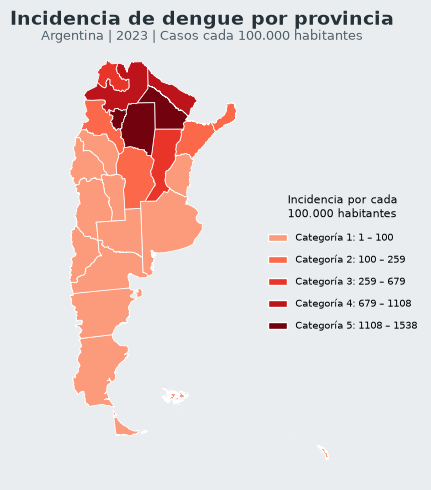

In [13]:
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
from matplotlib.patches import Patch
from shapely.geometry import box

# --------------------------------------------------
# 1. Preparar geometrías para visualización
# --------------------------------------------------

# Trabajar siempre sobre una copia
gdf_mapa = gdf_analisis.copy()

# Asegurar que las geometrías estén en coordenadas geográficas
gdf_mapa = gdf_mapa.to_crs(epsg=4326)

# Definir el área visible:
# incluye Argentina continental, Tierra del Fuego y Malvinas
# excluye la extensión antártica
area_visible = box(-74, -56, -25, -21)

# Recortar las geometrías SIN eliminar provincias completas
gdf_mapa["geometry"] = gdf_mapa.geometry.intersection(area_visible)

# Eliminar únicamente geometrías vacías, si las hubiera
gdf_mapa = gdf_mapa[
    ~gdf_mapa.geometry.is_empty
].copy()

# Proyectar a POSGAR 2007 / Argentina 5
gdf_mapa = gdf_mapa.to_crs(epsg=5347)

# --------------------------------------------------
# 2. Definir paleta de colores
# --------------------------------------------------

# Paleta de rojos y bordó, con contraste reforzado

paleta = plt.colormaps["Reds"]
colores = paleta([0.35, 0.50, 0.65, 0.80, 0.98])
paleta_contraste = mcolors.ListedColormap(colores)

# --------------------------------------------------
# 3. Definir rangos y categorías
# --------------------------------------------------

bins = clasificador.bins

minimo = df_analisis["incidencia_100mil"].min()

limites = [minimo] + list(bins)

etiquetas = [
    f"{limites[i]:.0f} – {limites[i+1]:.0f}"
    for i in range(len(limites) - 1)
]

elementos_leyenda = []

for i, etiqueta in enumerate(etiquetas):
    elementos_leyenda.append(
        Patch(
            facecolor=colores[i],
            edgecolor="white",
            label=f"Categoría {i+1}: {etiqueta}"
        )
    )

# --------------------------------------------------
# 4. Crear mapa
# --------------------------------------------------

fig, ax = plt.subplots(figsize=(7, 5))

gdf_mapa.plot(
    column="categoria_incidencia",
    categorical=True,
    cmap=paleta_contraste,
    linewidth=0.6,
    edgecolor="white",
    ax=ax
)

# --------------------------------------------------
# 5. Título y subtítulo
# --------------------------------------------------

ax.set_title(
    "Incidencia de dengue por provincia",
    fontsize=14,
    fontweight="bold",
    color="#263238",
    pad=14
)

ax.text(
    0.5, 1.01,
    "Argentina | 2023 | Casos cada 100.000 habitantes",
    transform=ax.transAxes,
    ha="center",
    fontsize=9,
    color="#52616B"
)

# --------------------------------------------------
# 6. Leyenda externa
# --------------------------------------------------

ax.legend(
    handles=elementos_leyenda,
    title="Incidencia por cada\n100.000 habitantes",
    loc="center left",
    bbox_to_anchor=(0.7, 0.5),
    frameon=False,
    fontsize=7,
    title_fontsize=8,
    labelspacing=1.2
)

# --------------------------------------------------
# 7. Fondo, encuadre y proporciones
# --------------------------------------------------

ax.set_facecolor("#E9EDF0")
fig.patch.set_facecolor("#E9EDF0")

xmin, ymin, xmax, ymax = gdf_mapa.total_bounds

margen_x = (xmax - xmin) * 0.04
margen_y = (ymax - ymin) * 0.04

ax.set_xlim(xmin - margen_x, xmax + margen_x)
ax.set_ylim(ymin - margen_y, ymax + margen_y)

ax.set_aspect("equal")
ax.axis("off")

plt.tight_layout(rect=[0, 0, 0.76, 1])

plt.show()


In [31]:
# --------------------------------------------------
# 8. Exportar visualización
# --------------------------------------------------

OUTPUT_DIR = PROJECT_DIR / "outputs" / "figures"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Guardar imagen PNG en alta resolución
fig.savefig(
    OUTPUT_DIR / "mapa_incidencia_dengue_2023.png",
    dpi=300,
    bbox_inches="tight",
    facecolor=fig.get_facecolor()
)

# Guardar versión PDF vectorial
fig.savefig(
    OUTPUT_DIR / "mapa_incidencia_dengue_2023.pdf",
    bbox_inches="tight",
    facecolor=fig.get_facecolor()
)

print("Visualizaciones guardadas en:", OUTPUT_DIR)


Visualizaciones guardadas en: C:\Users\luisi\Desktop\Bioinformatica\Data Science\Data science II\dengue_spatial_storytelling\outputs\figures


### 2. Ranking de provincias con mayor incidencia

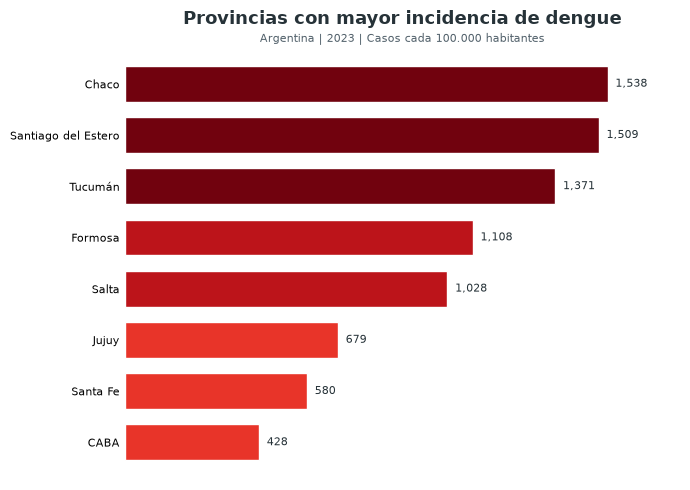

In [14]:
# Seleccionar las 8 provincias con mayor incidencia
top_8 = (
    df_analisis
    .sort_values("incidencia_100mil", ascending=False)
    .head(8)
    .sort_values("incidencia_100mil", ascending=True)
)

# Asignar a cada provincia el color de su categoría del mapa
colores_barras = [
    colores[int(categoria) - 1]
    for categoria in top_8["categoria_incidencia"]
]

# Crear figura
fig, ax = plt.subplots(figsize=(7, 5))

# Gráfico de barras
barras = ax.barh(
    top_8["provincia_residencia"],
    top_8["incidencia_100mil"],
    color=colores_barras,
    edgecolor="white",
    height=0.7
)

# Etiquetas de incidencia al final de cada barra
for barra in barras:
    ancho = barra.get_width()
    ax.text(
        ancho + 25,
        barra.get_y() + barra.get_height() / 2,
        f"{ancho:,.0f}",
        va="center",
        fontsize=8,
        color="#263238"
    )

# Título y subtítulo
ax.set_title(
    "Provincias con mayor incidencia de dengue",
    fontsize=13,
    fontweight="bold",
    color="#263238",
    pad=16
)

ax.text(
    0.5, 1.01,
    "Argentina | 2023 | Casos cada 100.000 habitantes",
    transform=ax.transAxes,
    ha="center",
    fontsize=8,
    color="#52616B"
)

# Estética
ax.set_xlabel("")
ax.set_ylabel("")

colores = [
    "#F4A6A6",  # Categoría 1: rosa
    "#E76F51",  # Categoría 2: coral
    "#D62828",  # Categoría 3: rojo intenso
    "#9D0208",  # Categoría 4: rojo oscuro
    "#590D22"   # Categoría 5: bordó profundo
]

paleta_contraste = mcolors.ListedColormap(colores)

# Quitar etiquetas numéricas del eje X
ax.set_xticks([])

# Mantener líneas guía verticales suaves
ax.grid(axis="x", linestyle="--", alpha=0.2)
ax.set_axisbelow(True)

# Limpiar bordes
ax.spines[["top", "right", "left", "bottom"]].set_visible(False)
ax.tick_params(axis="y", length=0, labelsize=8)

# Espacio para las etiquetas
ax.set_xlim(0, top_8["incidencia_100mil"].max() * 1.15)

plt.tight_layout()
plt.show()

In [39]:
# Guardar gráfico de barras
OUTPUT_DIR = PROJECT_DIR / "outputs" / "figures"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

fig.savefig(
    OUTPUT_DIR / "top8_incidencia_dengue_2023.png",
    dpi=300,
    bbox_inches="tight",
    facecolor="#E9EDF0"
)

fig.savefig(
    OUTPUT_DIR / "top8_incidencia_dengue_2023.pdf",
    bbox_inches="tight",
    facecolor="#E9EDF0"
)

print("Gráfico guardado correctamente en:", OUTPUT_DIR)

Gráfico guardado correctamente en: C:\Users\luisi\Desktop\Bioinformatica\Data Science\Data science II\dengue_spatial_storytelling\outputs\figures


### 3. Tabla comparativa y Grafico de pendientes

In [15]:
# Crear rankings
comparacion = df_analisis[
    ["provincia_residencia", "casos", "incidencia_100mil"]
].copy()

comparacion["ranking_casos"] = (
    comparacion["casos"]
    .rank(method="min", ascending=False)
    .astype(int)
)

comparacion["ranking_incidencia"] = (
    comparacion["incidencia_100mil"]
    .rank(method="min", ascending=False)
    .astype(int)
)

# Diferencia entre posiciones
comparacion["diferencia_ranking"] = (
    comparacion["ranking_casos"] -
    comparacion["ranking_incidencia"]
)

# Mostrar las 8 provincias con mayor incidencia
comparacion.sort_values(
    "ranking_incidencia"
).head(8)

,provincia_residencia,casos,incidencia_100mil,ranking_casos,ranking_incidencia,diferencia_ranking
0,Chaco,18369,1537.629611,3,1,2
1,Santiago del Estero,15843,1509.417784,4,2,2
2,Tucumán,24172,1370.886193,1,3,-2
3,Formosa,6898,1108.240632,9,4,5
4,Salta,15145,1027.566185,5,5,0
5,Jujuy,5410,678.909628,10,6,4
6,Santa Fe,21328,580.454670,2,7,-5
7,CABA,13292,427.685114,6,8,-2


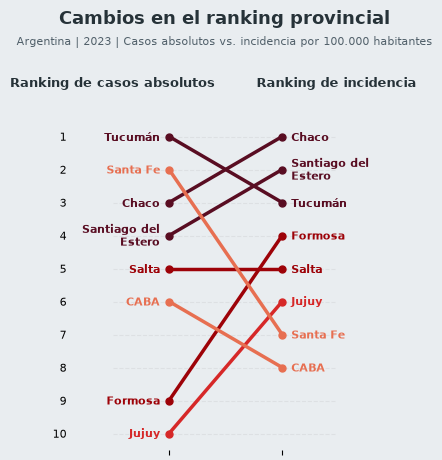

In [16]:
# Seleccionar las 8 provincias con mayor incidencia
provincias_relevantes = (
    df_analisis
    .nlargest(8, "incidencia_100mil")["provincia_residencia"]
    .tolist()
)

comparacion_relevante = comparacion[
    comparacion["provincia_residencia"].isin(provincias_relevantes)
].copy()

# Colores por provincia, manteniendo la identidad visual
provincias_destacadas = {
    "Chaco": "#590D22",
    "Santiago del Estero": "#590D22",
    "Tucumán": "#590D22",
    "Formosa": "#9D0208",
    "Salta": "#9D0208",
    "Jujuy": "#D62828",
    "Santa Fe": "#E76F51",
    "CABA": "#E76F51"
}

# Crear figura
fig, ax = plt.subplots(figsize=(7, 5))

# Dibujar líneas y etiquetas
for _, fila in comparacion_relevante.iterrows():

    provincia = fila["provincia_residencia"]
    color = provincias_destacadas[provincia]

    # Adaptar nombre largo
    nombre = (
        "Santiago del\nEstero"
        if provincia == "Santiago del Estero"
        else provincia
    )

    # Línea entre ambos rankings
    ax.plot(
        [0, 1],
        [fila["ranking_casos"], fila["ranking_incidencia"]],
        color=color,
        linewidth=2.5,
        marker="o",
        markersize=5,
        zorder=3
    )

    # Etiqueta izquierda: ranking de casos
    ax.text(
        -0.08,
        fila["ranking_casos"],
        nombre,
        ha="right",
        va="center",
        fontsize=8,
        color=color,
        fontweight="bold",
        linespacing=1.1
    )

    # Etiqueta derecha: ranking de incidencia
    ax.text(
        1.08,
        fila["ranking_incidencia"],
        nombre,
        ha="left",
        va="center",
        fontsize=8,
        color=color,
        fontweight="bold",
        linespacing=1.1
    )

# Configuración de ejes
ax.set_xlim(-0.50, 1.48)
ax.set_ylim(10.5, 0.5)

ax.set_xticks([0, 1])
ax.set_xticklabels([])

ax.set_yticks(range(1, 11))
ax.tick_params(
    axis="y",
    length=0,
    labelsize=8,
    pad=33
)

# Títulos superiores de los rankings
ax.text(
    0, 1.10,
    "Ranking de casos absolutos",
    transform=ax.transAxes,
    ha="center",
    fontsize=9,
    fontweight="bold",
    color="#263238"
)

ax.text(
    1, 1.10,
    "Ranking de incidencia",
    transform=ax.transAxes,
    ha="center",
    fontsize=9,
    fontweight="bold",
    color="#263238"
)

# Título principal
fig.suptitle(
    "Cambios en el ranking provincial",
    fontsize=13,
    fontweight="bold",
    color="#263238",
    y=0.98
)

# Subtítulo
fig.text(
    0.5, 0.91,
    "Argentina | 2023 | Casos absolutos vs. incidencia por 100.000 habitantes",
    ha="center",
    fontsize=8,
    color="#52616B"
)

# Estética general
ax.set_facecolor("#E9EDF0")
fig.patch.set_facecolor("#E9EDF0")

ax.grid(
    axis="y",
    linestyle="--",
    alpha=0.2
)

ax.set_axisbelow(True)

ax.spines[["top", "right", "left", "bottom"]].set_visible(False)

# Espaciado general
plt.subplots_adjust(
    left=0.34,
    right=0.66,
    top=0.76,
    bottom=0.10
)

plt.show()

In [57]:
# Guardar gráfico comparativo de rankings
OUTPUT_DIR = PROJECT_DIR / "outputs" / "figures"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

fig.savefig(
    OUTPUT_DIR / "comparacion_ranking_dengue_2023.png",
    dpi=300,
    bbox_inches="tight",
    facecolor="#E9EDF0"
)

fig.savefig(
    OUTPUT_DIR / "comparacion_ranking_dengue_2023.pdf",
    bbox_inches="tight",
    facecolor="#E9EDF0"
)

print("Gráfico comparativo guardado correctamente en:", OUTPUT_DIR)

Gráfico comparativo guardado correctamente en: C:\Users\luisi\Desktop\Bioinformatica\Data Science\Data science II\dengue_spatial_storytelling\outputs\figures


## Interpretación de resultados y hallazgos principales

### 1. Diferencias entre casos absolutos e incidencia

El análisis muestra que la distribución de los casos absolutos de dengue no coincide necesariamente con la distribución de la incidencia relativa entre las provincias.

Tucumán registra la mayor cantidad de casos (24.172), pero ocupa el tercer lugar en incidencia (1.370,89 casos cada 100.000 habitantes). En cambio, Chaco presenta la incidencia más elevada del país (1.537,63), aunque ocupa el tercer lugar en cantidad de casos.

Esta diferencia evidencia la importancia de considerar el tamaño de la población al comparar la carga epidemiológica entre jurisdicciones.

### 2. Concentración territorial de las mayores incidencias

Las cinco provincias con mayor incidencia son Chaco, Santiago del Estero, Tucumán, Formosa y Salta. Las cinco pertenecen al norte argentino.

Este patrón permite identificar una concentración territorial de las mayores incidencias durante el período analizado, aunque los datos utilizados no permiten establecer las causas de esa distribución.

### 3. Diferencias en la posición relativa de las provincias

La comparación de rankings permite observar cambios importantes según la medida utilizada:

- Formosa pasa del noveno puesto en cantidad de casos al cuarto en incidencia.
- Chaco pasa del tercer puesto al primero.
- Santa Fe desciende del segundo puesto en casos absolutos al séptimo en incidencia.
- CABA pasa del sexto puesto en casos absolutos al octavo en incidencia.
- Tucumán desciende del primer puesto en casos al tercero en incidencia.

Estos resultados muestran que el ordenamiento territorial cambia considerablemente cuando se incorpora la población como denominador.

### Síntesis

El análisis confirma que los casos absolutos y la incidencia representan dimensiones diferentes de la distribución territorial del dengue. Mientras los primeros reflejan el volumen de casos registrados, la incidencia permite comparar la frecuencia relativa del evento entre poblaciones de distinto tamaño.

## Hipótesis y perspectivas de investigación futura

### Posibles factores asociados a la distribución territorial

Los patrones espaciales observados plantean interrogantes sobre los factores que podrían contribuir a explicar las diferencias de incidencia entre provincias.

La bibliografía científica identifica múltiples dimensiones asociadas a la transmisión del dengue, entre ellas las condiciones climáticas, las características ambientales, la densidad poblacional, la urbanización y las condiciones socioeconómicas.

En particular, investigaciones realizadas en Argentina han señalado que la distribución del dengue no puede explicarse únicamente mediante variables climáticas, sino que requiere considerar también factores demográficos y geográficos.

A partir de estos antecedentes, se plantean las siguientes hipótesis para futuras investigaciones:

- Las condiciones de temperatura, humedad y precipitaciones podrían contribuir a explicar diferencias territoriales en la favorabilidad ambiental para la transmisión.
- La densidad poblacional, la urbanización y la movilidad humana podrían influir en los patrones de exposición y propagación.
- Las condiciones de vivienda, el acceso al agua potable y los servicios de saneamiento podrían contribuir a identificar territorios con mayor vulnerabilidad socioambiental.
- La presencia del vector y los antecedentes epidemiológicos podrían aportar información relevante para anticipar períodos y zonas de mayor transmisión.

Estas hipótesis no fueron evaluadas directamente en el presente análisis y no constituyen explicaciones demostradas de las diferencias observadas.

### Variables propuestas para futuras investigaciones

Se propone ampliar el análisis mediante la integración de información climática, ambiental, sociodemográfica, socioeconómica, epidemiológica y entomológica.

Una mayor disponibilidad de datos, preferentemente desagregados a escala departamental y temporalmente vinculados con las semanas epidemiológicas, permitiría investigar las relaciones entre estas dimensiones.

### Aplicaciones potenciales de modelos predictivos

La integración de estas variables podría permitir desarrollar modelos estadísticos y de machine learning orientados a:

- Estimar la incidencia esperada de dengue en diferentes territorios y períodos.
- Identificar patrones espaciales y temporales asociados con una mayor transmisión.
- Detectar territorios con condiciones de vulnerabilidad socioambiental.
- Reconocer combinaciones de factores que podrían favorecer la aparición de brotes.
- Generar información para orientar estrategias de vigilancia epidemiológica, prevención y asignación de recursos sanitarios.

El desarrollo de estas herramientas requeriría series históricas suficientemente extensas, datos de mayor resolución espacial y temporal, y procesos de validación que permitan evaluar su capacidad predictiva.

### Alcance de la propuesta

El presente trabajo constituye una primera aproximación descriptiva y espacial a la distribución del dengue en Argentina durante 2023. Sus resultados permiten identificar diferencias territoriales en la incidencia y formular nuevas preguntas de investigación, pero no permiten establecer relaciones causales ni estimar la vulnerabilidad integral de cada provincia.

## Metodología, fuentes y limitaciones

### Fuentes de datos

Para el desarrollo del análisis se utilizaron las siguientes fuentes:

- **Ministerio de Salud de la Nación:** registros de vigilancia epidemiológica de dengue y zika correspondientes a las semanas epidemiológicas 1 a 52 de 2023 y 2024.
- **INDEC:** proyecciones de población por jurisdicción para el año 2023, considerando ambos sexos y la población estimada al 1 de julio.
- **Georef Argentina:** geometrías geográficas provinciales utilizadas para la representación cartográfica.

### Alcance temporal y geográfico

El análisis se limita a los registros correspondientes al año calendario 2023, desde la semana epidemiológica 1 hasta la 52, considerando exclusivamente el evento dengue.

La unidad de análisis es la provincia. Se incluyeron las 24 jurisdicciones argentinas.

### Procesamiento y metodología

Los registros epidemiológicos fueron agrupados por provincia de residencia y se calcularon los casos totales correspondientes al período analizado.

Posteriormente, se integraron los datos de población proyectada para calcular la incidencia acumulada por cada 100.000 habitantes:

**Incidencia = (Casos registrados / Población estimada) × 100.000**

Se realizaron uniones entre los datos epidemiológicos, demográficos y geográficos para construir el conjunto de datos provincial utilizado en las visualizaciones.

Para representar la distribución espacial de la incidencia se utilizó el método de clasificación Jenks Natural Breaks, con cinco categorías. Estas categorías responden a una clasificación estadística de los valores observados y no representan niveles oficiales de riesgo epidemiológico.

### Consideraciones sobre la calidad de los datos

Durante la exploración se identificaron registros duplicados y claves repetidas con cantidades diferentes. Dado que no fue posible determinar de manera concluyente cuáles correspondían a errores, se conservaron los registros originales para evitar eliminar casos potencialmente válidos.

Se identificaron 468 casos sin provincia de residencia especificada, que fueron excluidos del análisis territorial.

El conjunto de datos contiene 146.876 casos en total, de los cuales 146.408 cuentan con provincia identificada.

El total provincial identificado presenta una diferencia respecto del total de 139.946 casos informado en el Boletín Epidemiológico Nacional para el año calendario 2023. Esta discrepancia no pudo reconciliarse con la información disponible y debe considerarse al interpretar los resultados.

### Limitaciones

- El análisis utiliza datos agregados a escala provincial, por lo que no permite identificar diferencias internas entre departamentos o localidades.
- La incidencia fue calculada utilizando población proyectada y no mediciones poblacionales directas.
- No se incorporaron variables climáticas, ambientales, socioeconómicas ni entomológicas.
- El análisis es descriptivo y exploratorio, por lo que no permite establecer relaciones causales ni identificar factores explicativos de las diferencias territoriales.
- Las diferencias en los registros epidemiológicos respecto de otras publicaciones oficiales limitan la comparabilidad directa de los totales.

### Reproducibilidad

El procesamiento de datos se encuentra documentado en el notebook `01_exploracion_geoespacial.ipynb`. El análisis espacial, las visualizaciones y la interpretación de resultados se desarrollan en el presente notebook.

Los conjuntos de datos procesados y las figuras generadas se almacenan en las carpetas `data/processed/` y `outputs/figures/`, respectivamente.